/tmp/ipykernel_58/4201778974.py:26: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




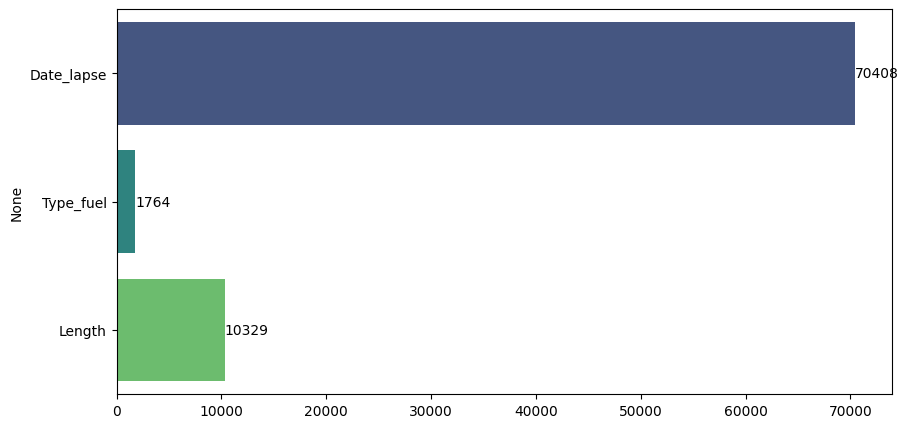

Negative vehicle ages: 0


/tmp/ipykernel_58/4201778974.py:113: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




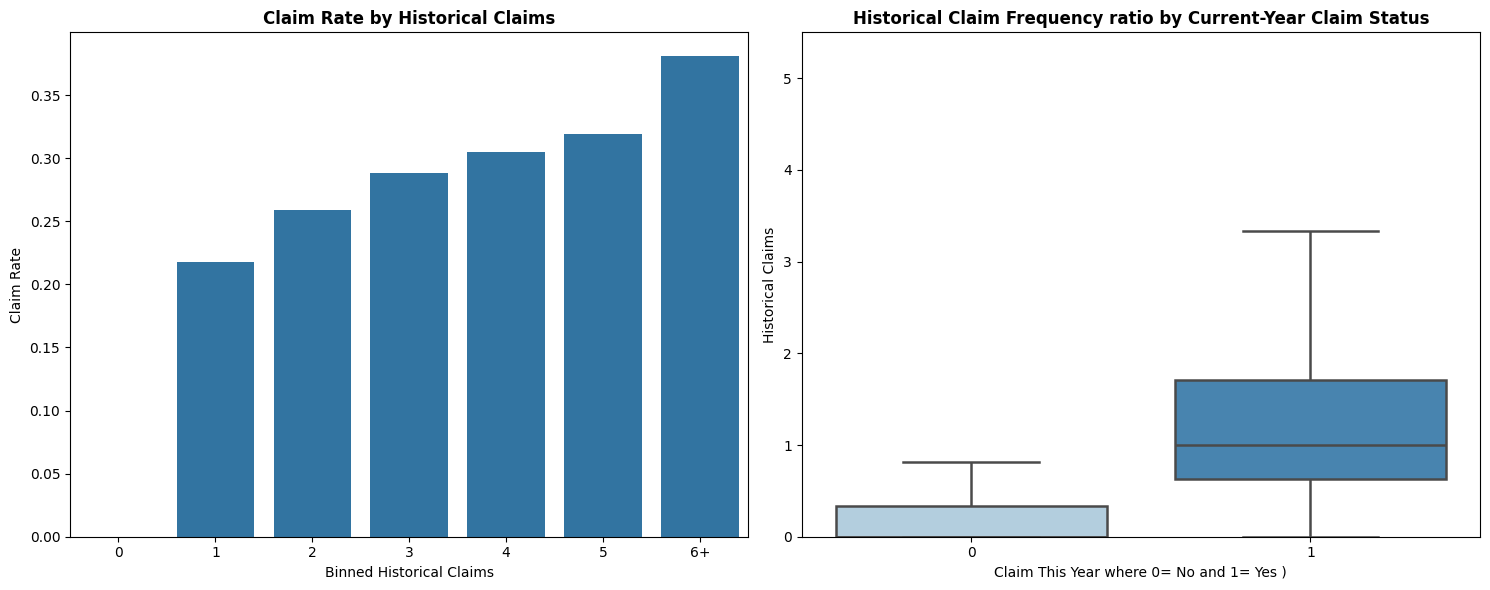

/tmp/ipykernel_58/4201778974.py:136: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_58/4201778974.py:137: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_58/4201778974.py:144: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




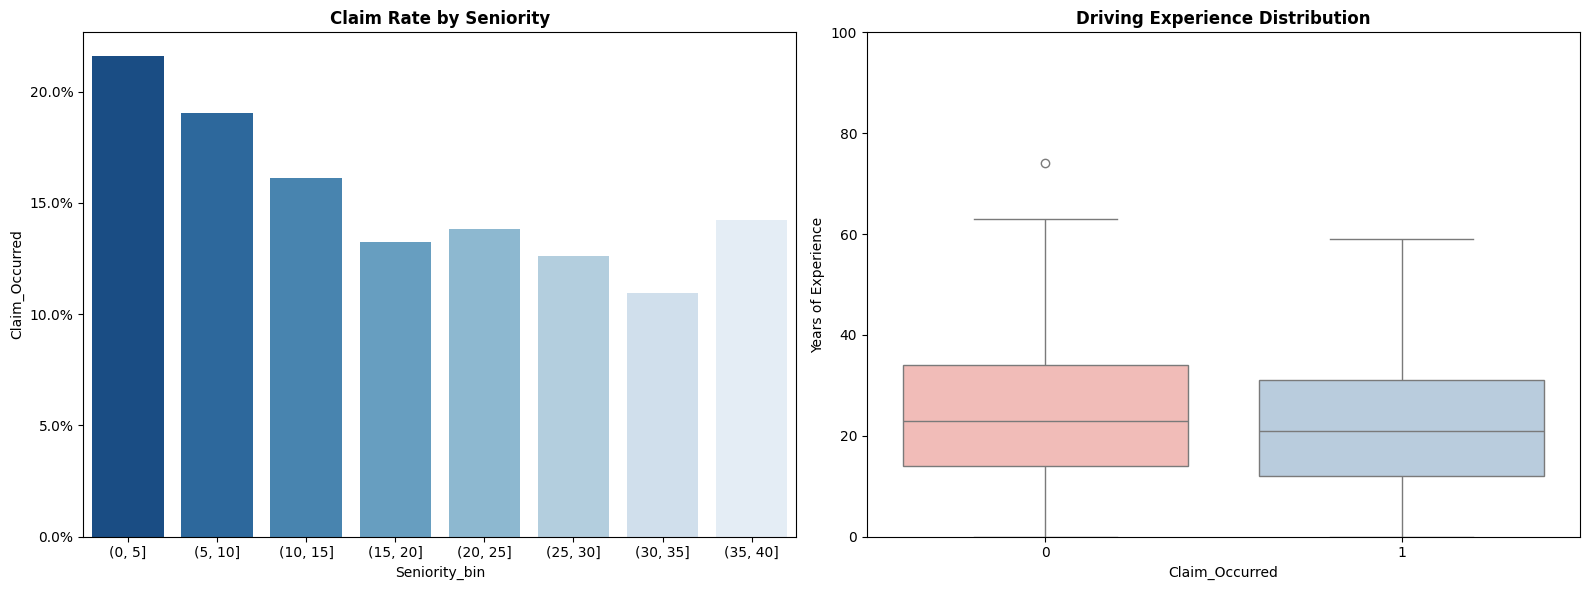

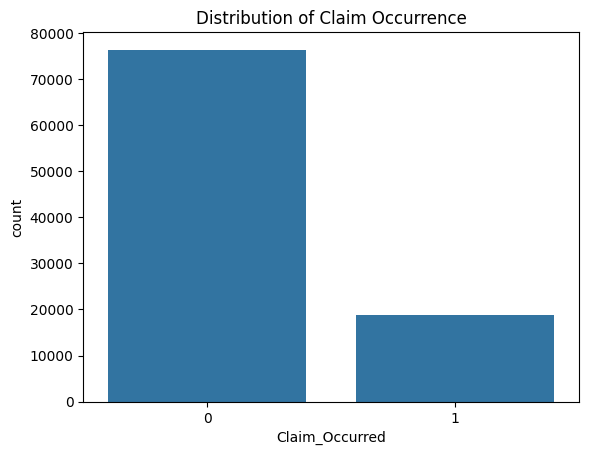

Claim_Occurred
0    76428
1    18798
Name: count, dtype: int64


/tmp/ipykernel_58/4201778974.py:167: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_58/4201778974.py:174: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




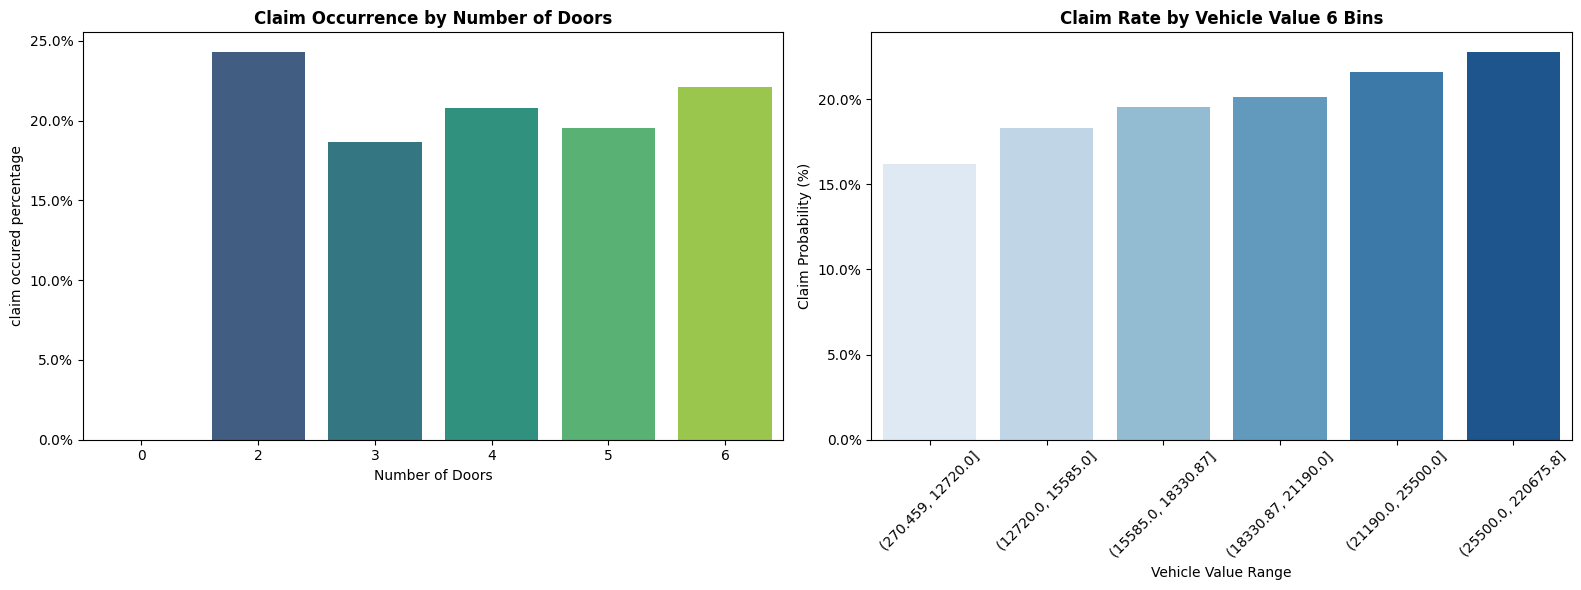

Data size : (95226, 65)
Claim rate : 0.19740407031693025
Total features : 47
Claim_Occurred
0    76428
1    18798
Name: count, dtype: int64
Train: (66658, 47)
Validation: (14284, 47)
Test: (14284, 47)


In [8]:
#eda and split



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
import plotly.express as px
import warnings
import seaborn as sns
import matplotlib.ticker as mtick

np.random.seed(42)

df = pd.read_excel('/kaggle/input/datasets/umairkhan1324/motorr3/motorr.xlsx')
df = df.replace("NA", np.nan)
missing_values = df.isnull().sum()
# filtering for columns with missing values
missing_val = missing_values[missing_values > 0]
plt.figure(figsize=(10, 5))
# plotting barplot
bplot = sns.barplot(x=missing_val.values, y=missing_val.index, palette='viridis')
# adding data label to bars
for label in bplot.containers:
    bplot.bar_label(label)

plt.show()

# feature engineering
df = df.drop(columns=['Date_lapse'], errors='ignore')

df = df.dropna()



df['Date_last_renewal'] = pd.to_datetime(df['Date_last_renewal'], dayfirst=True, errors='coerce')
df['Date_birth'] = pd.to_datetime(df['Date_birth'], dayfirst=True, errors='coerce')
df['Date_start_contract'] = pd.to_datetime(df['Date_start_contract'], dayfirst=True, errors='coerce')
df['Date_driving_licence'] = pd.to_datetime(df['Date_driving_licence'], dayfirst=True, errors='coerce')


# derived attributes
df['age'] = (df['Date_last_renewal'] - df['Date_birth']).dt.days // 365
df['age_at_license'] = (df['Date_driving_licence'] - df['Date_birth']).dt.days // 365



# driving experience calculated from date of license to last renewal date
df['driving_experience'] = (df['Date_last_renewal'] - df['Date_driving_licence']).dt.days // 365
df['driving_experience'] = df['driving_experience'].clip(lower=0)
# binary indicator
df['Early_license'] = (df['driving_experience'] < 1).astype(int)
# target variable claim occurred which is a binary indicator of the n claims year column which shows number of claims of the poilicyholder in a year
df['Claim_Occurred'] = (df['N_claims_year'] > 0).astype(int)
df['Year_matriculation'] = pd.to_numeric(df['Year_matriculation'], errors='coerce')
# deriving vehicle age
df['Vehicle_Age'] = (df['Date_last_renewal'].dt.year - df['Year_matriculation']).clip(lower=0)

# selecting non null values of type fuel
df = df[(df['Type_fuel'] == 'P') | (df['Type_fuel'] == 'D')]

matrix = df.corr(numeric_only=True)
fig = px.imshow(matrix, text_auto=".2f", title="Correlation Heatmap", width=7500, height=1800)
fig.show()

# converting continuus variables to bins / categorical data to enhance understanding of risk across bins / groups
df['Length_class'] = pd.qcut(df['Length'], q=5, labels=False, duplicates='drop')
df['power_class'] = pd.qcut(df['Power'], q=4, labels=False, duplicates='drop')
df['value_class'] = pd.qcut(df['Value_vehicle'], q=6, labels=False, duplicates='drop')
df['cyl_class']    = pd.qcut(df['Cylinder_capacity'], q=5, labels=False, duplicates='drop')
df['Weight_class'] = pd.qcut(df['Weight'], q=5, labels=False, duplicates='drop')

# dropping null values
df = df.dropna()


# categorical values
cat_cols = ['Type_fuel', 'Second_driver', 'N_doors', 'Payment', 'Length_class',
'power_class', 'value_class', 'Distribution_channel', 'Area', 'Type_risk', 'Early_license','cyl_class','Weight_class']


# grouping all people with past claims more than 6
df['n_claims_hist_bin'] = df['N_claims_history'].clip(upper=6)




#
df['R_Claims_history_clipped'] = df['R_Claims_history'].clip(upper=5)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# representing all claims equal to or more than 6 as 6+
df['n_claims_hist_bin'] = df['n_claims_hist_bin'].astype(str).replace('6', '6+')


# grouping by claim history and resetting index
claim_rate = df.groupby('n_claims_hist_bin')['Claim_Occurred'].mean().reset_index()

# plotting barplot
sns.barplot(x='n_claims_hist_bin', y='Claim_Occurred', data=claim_rate, ax=ax1)

ax1.set_title('Claim Rate by Historical Claims', fontweight='bold', fontsize=12)
ax1.set_xlabel('Binned Historical Claims')
ax1.set_ylabel('Claim Rate')
ax1.grid(False, axis='both')

# Boxplot showing historical claim rate against claim rate
sns.boxplot(x='Claim_Occurred', y='R_Claims_history_clipped', data=df, ax=ax2, palette='Blues', linewidth=1.8, fliersize=0)
ax2.set_title('Historical Claim Frequency ratio by Current-Year Claim Status', fontweight='bold', fontsize=12)
ax2.set_xlabel('Claim This Year where 0= No and 1= Yes )')
ax2.set_ylabel('Historical Claims')
ax2.set_ylim(0, 5.5) # limiting y axis 
ax2.grid(False, axis='both')


plt.tight_layout()
plt.show()



# creating bins of seniority column to group by seniority
df['Seniority_bin'] = pd.cut(df['Seniority'], bins=range(0, 45, 5), right=True)



# another figure repreesnting seniority against claim and driving experience against claim

fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(16, 6))

# grouping by bins created
seniority_rate = df.groupby('Seniority_bin')['Claim_Occurred'].mean().reset_index()
sns.barplot(x='Seniority_bin', y='Claim_Occurred', data=seniority_rate, palette='Blues_r', ax=ax3)
ax3.set_title('Claim Rate by Seniority', fontweight='bold')

# representing claim as a percent
ax3.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# displaying boxplot of claim occurred against driving experiemce to see iif the average driver who claimed during the current year has more or less driving experience
sns.boxplot(x='Claim_Occurred', y='driving_experience', data=df, ax=ax4, palette='Pastel1')
ax4.set_title('Driving Experience Distribution', fontweight='bold')
ax4.set_ylabel('Years of Experience')
ax4.set_ylim(0, 100)
plt.tight_layout()
plt.show()


# countplot showing distribution of claim
sns.countplot(x='Claim_Occurred', data=df)
plt.title('Distribution of Claim Occurrence')
plt.show()
(print(df['Claim_Occurred'].value_counts()))


# creating 6 bins of vehicle value group
df['Value_Group'] = pd.qcut(df['Value_vehicle'], q=6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))



# plotting n doors against claim occcured
sns.barplot(x='N_doors', y='Claim_Occurred', data=df, ax=ax1, palette='viridis', errorbar=None)
ax1.set_title('Claim Occurrence by Number of Doors', fontweight='bold')
ax1.set_xlabel('Number of Doors')
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax1.set_ylabel('claim occured percentage')

# plotting value of vehicle against claim
sns.barplot(x='Value_Group', y='Claim_Occurred', data=df, ax=ax2, palette='Blues', errorbar=None)
ax2.set_title('Claim Rate by Vehicle Value 6 Bins', fontweight='bold')
ax2.set_xlabel('Vehicle Value Range')
ax2.set_ylabel('Claim Probability (%)')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show() 



df = pd.get_dummies(df, columns=cat_cols, drop_first=True)# non features including dates and column like n_claims_year and cost_claims year that may cause data leakage

non_features = ['ID','Date_birth','Date_driving_licence','Date_next_renewal','Date_last_renewal','Date_start_contract','N_claims_year','Cost_claims_year','Claim_Occurred',
    'Length',
    'Power',
    'Value_vehicle',
    'n_claims_hist_bin',
    'R_Claims_history_clipped',
    'Seniority_bin',
    'Value_Group',
    'Cylinder_capacity',
    'Weight'
]
feature_cols = [c for c in df.columns if c not in non_features]

X_all = df[feature_cols]       
y_all = df['Claim_Occurred']

print("Data size :", df.shape)
print("Claim rate :", y_all.mean())
print("Total features :", len(feature_cols))


print(df['Claim_Occurred'].value_counts())





#splitting to train and test dataset

X_train, X_t, y_train, y_t = train_test_split(
    X_all,
    y_all,
    test_size=0.30,
    stratify=y_all,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_t,
    y_t,
    test_size=0.50,
    stratify=y_t,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)



In [2]:
pip install rocauc_comparison

Note: you may need to restart the kernel to use updated packages.


In [4]:
#baseline glm


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import pytensor
import time
import random



scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

C_values = [0.01,0.1, 1, 10]
thresholds = np.arange(0.5, 0.9, 0.05)

best_score = 0
best_C = 1
best_threshold = 0.5

for C in C_values:
    lr = LogisticRegression(C=C, max_iter=2000, random_state=42, solver='lbfgs')
    lr.fit(X_train_res, y_train_res)
    val_probs = lr.predict_proba(X_val_s)[:, 1]
    for thresh in thresholds:
        preds = (val_probs >= thresh).astype(int)
        score = f1_score(y_val, preds)
        print(C,thresh,score)
        if score > best_score:
            best_score = score
            best_C = C
            best_threshold = thresh
    print(f"C={C} evaluated")

print(f"Best C: {best_C}")
print(f"Best threshold: {best_threshold}")

start_time = time.time()
lr = LogisticRegression(C=best_C, max_iter=2000, random_state=42, solver='lbfgs')
lr.fit(X_train_res, y_train_res)
training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

test_probs_glm = lr.predict_proba(X_test_s)[:, 1]
test_preds = (test_probs_glm >= best_threshold).astype(int)

print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(f"Precision: {precision_score(y_test, test_preds):.4f}")
print(f"Recall: {recall_score(y_test, test_preds):.4f}")
print(f"F1-Score: {f1_score(y_test, test_preds):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, test_probs_glm):.4f}")
print(f"Brier: {brier_score_loss(y_test, test_probs_glm):.4f}")
print(f"Training time: {training_time:.2f} seconds")

0.01 0.5 0.7280037111489098
0.01 0.55 0.7261064785118666
0.01 0.6000000000000001 0.7226044638362141
0.01 0.6500000000000001 0.7192737430167597
0.01 0.7000000000000002 0.7099457504520795
0.01 0.7500000000000002 0.695668549905838
0.01 0.8000000000000003 0.6689055709205848
0.01 0.8500000000000003 0.6309847376123772
C=0.01 evaluated
0.1 0.5 0.7318631178707224
0.1 0.55 0.7373257287705957
0.1 0.6000000000000001 0.7384968069428525
0.1 0.6500000000000001 0.7316823228010247
0.1 0.7000000000000002 0.722202486678508
0.1 0.7500000000000002 0.7087576374745418
0.1 0.8000000000000003 0.6845899084356127
0.1 0.8500000000000003 0.6479917610710607
C=0.1 evaluated
1 0.5 0.7298807187075343
1 0.55 0.735997482693518
1 0.6000000000000001 0.7386475008167266
1 0.6500000000000001 0.7336836751991863
1 0.7000000000000002 0.7224186704384724
1 0.7500000000000002 0.7097367936683232
1 0.8000000000000003 0.685814088880264
1 0.8500000000000003 0.6521739130434783
C=1 evaluated
10 0.5 0.7287803407206392
10 0.55 0.73619631

In [5]:
#baseline xgboost

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import time

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

n_estimators_list = [100, 200, 300]
max_depth_list = [3, 5, 7]
learning= [0.1, 0.01, 0.001]
thresholds = np.arange(0.5, 0.9, 0.05)

best_score = 0
best_n = 200
best_depth = 4
best_threshold = 0.5

for n in n_estimators_list:
    for d in max_depth_list:
        for l in learning:
            xg = xgb.XGBClassifier(
                n_estimators=n, max_depth=d, learning_rate=l,
                objective='binary:logistic', random_state=42, n_jobs=2)
            xg.fit(X_train_res, y_train_res)
            val_probs = xg.predict_proba(X_val_s)[:, 1]
            for thresh in thresholds:
                preds = (val_probs >= thresh).astype(int)
                score = f1_score(y_val, preds)
                print('n_est',n,'depth',d,'threshold',thresh,'score',score)
                if score > best_score:
                    best_score = score
                    best_n = n
                    best_depth = d
                    best_threshold = thresh
                    best_learning = l

print(f"Best n_estimators: {best_n}")
print(f"Best max_depth: {best_depth}")
print(f"Best threshold: {best_threshold}")
print(f"Best learnig: {best_learning}")

start_time = time.time()
final_xg = xgb.XGBClassifier(
    n_estimators=best_n, max_depth=best_depth, learning_rate=best_learning,
    objective='binary:logistic', random_state=42, n_jobs=2)
final_xg.fit(X_train_res, y_train_res)
training_time = time.time() - start_time
print(f"Final model training time: {training_time:.2f} seconds")

test_probs_xg = final_xg.predict_proba(X_test_s)[:, 1]
test_preds = (test_probs_xg >= best_threshold).astype(int)

print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(f"Precision: {precision_score(y_test, test_preds):.4f}")
print(f"Recall: {recall_score(y_test, test_preds):.4f}")
print(f"F1-Score: {f1_score(y_test, test_preds):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, test_probs_xg):.4f}")
print(f"Brier: {brier_score_loss(y_test, test_probs_xg):.4f}")
print(f"Training time: {training_time:.2f} seconds")


n_est 100 depth 3 threshold 0.5 score 0.7341929470250117
n_est 100 depth 3 threshold 0.55 score 0.7392996108949417
n_est 100 depth 3 threshold 0.6000000000000001 score 0.7391081496668375
n_est 100 depth 3 threshold 0.6500000000000001 score 0.7285843101893598
n_est 100 depth 3 threshold 0.7000000000000002 score 0.7151584574264986
n_est 100 depth 3 threshold 0.7500000000000002 score 0.6784305584388624
n_est 100 depth 3 threshold 0.8000000000000003 score 0.6160491020686519
n_est 100 depth 3 threshold 0.8500000000000003 score 0.5054777070063694
n_est 100 depth 3 threshold 0.5 score 0.6859675855381632
n_est 100 depth 3 threshold 0.55 score 0.6841505131128849
n_est 100 depth 3 threshold 0.6000000000000001 score 0.701216764308247
n_est 100 depth 3 threshold 0.6500000000000001 score 0.672606568832984
n_est 100 depth 3 threshold 0.7000000000000002 score 0.6572697431936667
n_est 100 depth 3 threshold 0.7500000000000002 score 0.5367717287488061
n_est 100 depth 3 threshold 0.8000000000000003 score

Output()

Finished [100%]: Average Loss = 245.69
Sampling: [likelihood]


Output()

  Best so far: F1=0.7603 with lr=0.01, thresh=0.60, prior=0.5


Output()

...

Finished [100%]: Average Loss = 268.11
Sampling: [likelihood]


Output()

  Best so far: F1=0.7694 with lr=0.01, thresh=0.60, prior=1.0


Output()

Finished [100%]: Average Loss = 243.32


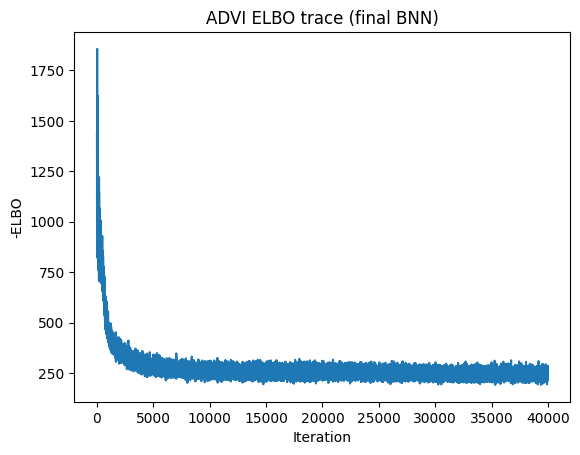

Sampling: [likelihood]


Output()

Final BNN training time: 113.68 seconds


Accuracy:  0.9045785494259311
Precision: 0.7173134328358209
Recall:    0.8524299396949273
F1-Score:  0.7790565731885233
AUC-ROC:   0.9575366025228781
Brier:     0.07647280245776986
Training time: 113.68 seconds
statistical test glm vs xgboost DelongTestResult(p_value=2.5871056240229234e-78, log10_p_value=-77.58718583993677)
statistical test glm vs bnn DelongTestResult(p_value=2.0632774127024996e-53, log10_p_value=-52.68544237614405)
statistical test bnn vs xgboost DelongTestResult(p_value=3.4374195980525944e-11, log10_p_value=-10.463767451279633)


In [14]:
#baseline bnn final

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import pymc as pm 
import pytensor
import time
import random
from rocauc_comparison import delong_roc_test
floatX = pytensor.config.floatX

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype(floatX)
X_val_s = scaler.transform(X_val).astype(floatX)
X_test_s = scaler.transform(X_test).astype(floatX)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)
X_train_res = X_train_res.astype(floatX)
y_train_res = y_train_res.astype(floatX)

# using 2 layers in the BNN with 30 and 15 neurons to improve prediction
input_dim = X_train.shape[1]

n_hidden   = 30
n_hidden_2 = 15

# ADVI iterations fixed (chosen via ELBO trace plot; hyperparamters learning rate and thresholds tuned
n_iters = 40000
learning_rate_list = [0.01, 0.001]
prior_sigmas = [0.5, 1.0]
thresholds = np.arange(0.5, 0.9, 0.05)

best_val_f1 = 0
best_lr = 0.001
best_threshold = 0.5
best_prior=0.5

for p in prior_sigmas:

    for l in learning_rate_list:

        coords = {
            "hidden_layer":   np.arange(n_hidden),
            "hidden_layer_2": np.arange(n_hidden_2),
            "features":       np.arange(input_dim),
            "obs":            np.arange(X_train_res.shape[0])
        }
        with pm.Model(coords=coords) as model:
            X_data = pm.Data("X_data", X_train_res, dims=("obs", "features"))
            Y_data = pm.Data("Y_data", y_train_res, dims="obs")
            ann_input, ann_output = pm.Minibatch(X_data, Y_data, batch_size=1024)

            weights_in   = pm.Normal("weights_in",   mu=0, sigma=p, dims=("features", "hidden_layer"))
            weights_in_2 = pm.Normal("weights_in_2", mu=0, sigma=p, dims=("hidden_layer", "hidden_layer_2"))
            weights_out  = pm.Normal("weights_out",  mu=0, sigma=p, dims="hidden_layer_2")

            hidden   = pm.math.tanh(pm.math.dot(ann_input, weights_in))
            hidden_1 = pm.math.tanh(pm.math.dot(hidden, weights_in_2))
            output   = pm.math.sigmoid(pm.math.dot(hidden_1, weights_out))

            #bernoulli likelihood for modelling binary claim prediction
            likelihood = pm.Bernoulli("out", output, observed=ann_output, total_size=X_train_res.shape[0])

            approx = pm.fit(n=n_iters, method="advi", obj_optimizer=pm.adam(learning_rate=l),random_seed=42)
            trace = approx.sample(15000,random_seed=42)  

        # Predict on validation set
        test_coords = {
            "hidden_layer":   np.arange(n_hidden),
            "hidden_layer_2": np.arange(n_hidden_2),
            "features":       np.arange(input_dim),
            "obs_test":       np.arange(X_val_s.shape[0])
        }
        with pm.Model(coords=test_coords) as pred_model:
            ann_input = pm.Data("X_test_data", X_val_s, dims=("obs_test", "features"))
            w_in_1  = pm.Normal("weights_in",   mu=0, sigma=p, dims=("features", "hidden_layer"))
            w_1_2   = pm.Normal("weights_in_2", mu=0, sigma=p, dims=("hidden_layer", "hidden_layer_2"))
            w_2_out = pm.Normal("weights_out",  mu=0, sigma=p, dims="hidden_layer_2")
            act_1   = pm.math.tanh(pm.math.dot(ann_input, w_in_1))
            act_2   = pm.math.tanh(pm.math.dot(act_1, w_1_2))
            act_out = pm.math.sigmoid(pm.math.dot(act_2, w_2_out))
            p_out = pm.Deterministic("p_out", act_out)
            likelihood = pm.Bernoulli("likelihood", act_out, shape=X_val_s.shape[0])
            ppc_val = pm.sample_posterior_predictive(trace, var_names=["likelihood", "p_out"],random_seed=42)

        val_probs = ppc_val.posterior_predictive["p_out"].values.mean(axis=(0, 1))

        # Evaluate thresholds for best f1 score for maximum performance
        for thresh in thresholds:
            preds = (val_probs >= thresh).astype(int)
            f1 = f1_score(y_val, preds)
            if f1 > best_val_f1:
                best_val_f1 = f1
                best_lr = l
                best_threshold = thresh
                best_prior=p

        print(f"  Best so far: F1={best_val_f1:.4f} with lr={best_lr}, thresh={best_threshold:.2f}, prior={best_prior}")


coords_final = {
    "hidden_layer":   np.arange(n_hidden),
    "hidden_layer_2": np.arange(n_hidden_2),
    "features":       np.arange(input_dim),
    "obs":            np.arange(X_train_res.shape[0])
}
with pm.Model(coords=coords_final) as final_model:
    X_data = pm.Data("X_data", X_train_res, dims=("obs", "features"))
    Y_data = pm.Data("Y_data", y_train_res, dims="obs")
    ann_input, ann_output = pm.Minibatch(X_data, Y_data, batch_size=1024)

    weights_in   = pm.Normal("weights_in",   mu=0, sigma=best_prior, dims=("features", "hidden_layer"))
    weights_in_2 = pm.Normal("weights_in_2", mu=0, sigma=best_prior, dims=("hidden_layer", "hidden_layer_2"))
    weights_out  = pm.Normal("weights_out",  mu=0, sigma=best_prior, dims="hidden_layer_2")

    hidden   = pm.math.tanh(pm.math.dot(ann_input, weights_in))
    hidden_1 = pm.math.tanh(pm.math.dot(hidden, weights_in_2))
    output   = pm.math.sigmoid(pm.math.dot(hidden_1, weights_out))
    

    likelihood = pm.Bernoulli("out", output, observed=ann_output, total_size=X_train_res.shape[0])

    start_time = time.time()
    approx_final = pm.fit(n=n_iters, method="advi", obj_optimizer=pm.adam(learning_rate=best_lr),random_seed=42)
    training_time = time.time() - start_time
    plt.plot(approx_final.hist)
    plt.xlabel("Iteration")
    plt.ylabel("-ELBO")
    plt.title("ADVI ELBO trace (final BNN)")
    plt.show()

    
    trace_final = approx_final.sample(15000,random_seed=42)
print(f"Final BNN training time: {training_time:.2f} seconds")


test_coords_final = {
    "hidden_layer":   np.arange(n_hidden),
    "hidden_layer_2": np.arange(n_hidden_2),
    "features":       np.arange(input_dim),
    "obs_test":       np.arange(X_test_s.shape[0])
}
with pm.Model(coords=test_coords_final) as final_pred_model:
    ann_input = pm.Data("X_test_data", X_test_s, dims=("obs_test", "features"))
    w_in_1  = pm.Normal("weights_in",   mu=0, sigma=best_prior, dims=("features", "hidden_layer"))
    w_1_2   = pm.Normal("weights_in_2", mu=0, sigma=best_prior, dims=("hidden_layer", "hidden_layer_2"))
    w_2_out = pm.Normal("weights_out",  mu=0, sigma=best_prior, dims="hidden_layer_2")
    act_1   = pm.math.tanh(pm.math.dot(ann_input, w_in_1))
    act_2   = pm.math.tanh(pm.math.dot(act_1, w_1_2))
    act_out = pm.math.sigmoid(pm.math.dot(act_2, w_2_out))
    p_out = pm.Deterministic("p_out", act_out) 
    likelihood = pm.Bernoulli("likelihood", act_out, shape=X_test_s.shape[0])
    ppc_test = pm.sample_posterior_predictive(trace_final, var_names=["likelihood", "p_out"],random_seed=42)

posterior_samples= ppc_test.posterior_predictive["likelihood"].values
p_samples= ppc_test.posterior_predictive["p_out"].values 
test_probs_bnn = p_samples.mean(axis=(0, 1))   
std_probs= p_samples.std(axis=(0, 1))  
test_preds = (test_probs_bnn >= best_threshold).astype(int)

r1= delong_roc_test(y_test, test_probs_glm,test_probs_xg)
r2= delong_roc_test(y_test, test_probs_glm,test_probs_bnn)
r3= delong_roc_test(y_test, test_probs_bnn,test_probs_xg)

#printing results
print(f"Accuracy:  {accuracy_score(y_test, test_preds)}")
print(f"Precision: {precision_score(y_test, test_preds)}")
print(f"Recall:    {recall_score(y_test, test_preds)}")
print(f"F1-Score:  {f1_score(y_test, test_preds)}")
print(f"AUC-ROC:   {roc_auc_score(y_test, test_probs_bnn)}")
print(f"Brier:     {brier_score_loss(y_test, test_probs_bnn)}")
print(f"Training time: {training_time:.2f} seconds")
print('statistical test glm vs xgboost',r1 )
print('statistical test glm vs bnn',r2 )
print('statistical test bnn vs xgboost',r3)

In [6]:
pip install PyImpetus

Note: you may need to restart the kernel to use updated packages.


In [7]:
#markov blanket

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import time
from PyImpetus import PPIMBC


mb_model = PPIMBC(
    model=xgb.XGBClassifier(
        n_estimators=40,
        max_depth=4,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=0.99,
        objective='binary:logistic',
        random_state=42,
        n_jobs=2,
    ),
    p_val_thresh=0.05,
    num_simul=15,
    simul_size=0.7,
    cv=3,
    simul_type=1,
    verbose=1,
    random_state=42
)

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

mb_model.fit(X_train, y_train)
mb_features = mb_model.MB

print("length of features", len(mb_features), "features", mb_features)

X_train_mb = X_train[mb_features]
X_val_mb = X_val[mb_features]
X_test_mb = X_test[mb_features]

X_train_mb = X_train_mb.values
X_val_mb = X_val_mb.values
X_test_mb = X_test_mb.values
y_train = y_train.values
y_val = y_val.values
y_test = y_test.values

Progress bar:   0%|          | 0/3 [00:00<?, ?it/s][Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    6.1s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    6.9s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    6.9s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    7.5s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    6.4s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    6.4s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    7.9s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    7.9s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    8.0s finished
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:    7.9s finis

length of features 12 features ['Seniority', 'Policies_in_force', 'Lapse', 'Premium', 'N_claims_history', 'R_Claims_history', 'Year_matriculation', 'Vehicle_Age', 'Payment_1', 'driving_experience', 'age', 'Distribution_channel_1']


In [9]:

# mb-glm
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import time

# Scale features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_mb)
X_val_s = scaler.transform(X_val_mb)
X_test_s = scaler.transform(X_test_mb)

# SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

# C regularization strength values
C_values = [0.01, 0.1, 1, 10]
# threshold vals
thresholds = np.arange(0.5, 0.9, 0.05)

best_val_f1 = 0
best_C = 1
best_threshold = 0.5

# iterating over c values on validation data and finding best params
for C in C_values:
    lr = LogisticRegression(C=C, max_iter=2000, random_state=42, solver='lbfgs')
    lr.fit(X_train_res, y_train_res)
    

    val_probs = lr.predict_proba(X_val_s)[:,1]
    # using logistic regression probs to optimize threshold
    for thresh in thresholds:
        preds = (val_probs >= thresh).astype(int)
        f1 = f1_score(y_val, preds)
        
        if f1 > best_val_f1:
            best_val_f1 = f1
            best_C = C
            best_threshold = thresh
            print("c value",best_C,"f1",best_val_f1)

# tracking time
start_time = time.time()
# fitting model on test data with best params
final_lr = LogisticRegression(C=best_C, max_iter=2000, random_state=42, solver='lbfgs')
final_lr.fit(X_train_res, y_train_res)
training_time = time.time() - start_time
print(f"Final model training time: {training_time:.2f} seconds")

test_probs_mglm = final_lr.predict_proba(X_test_s)[:,1]
# using the best threshold we optimized
test_preds = (test_probs_mglm >= best_threshold).astype(int)
print(best_C)
print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(f"Precision: {precision_score(y_test, test_preds):.4f}")
print(f"Recall: {recall_score(y_test, test_preds):.4f}")
print(f"F1-Score: {f1_score(y_test, test_preds):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, test_probs_mglm):.4f}")
print(f"Brier: {brier_score_loss(y_test, test_probs_mglm):.4f}")
print(f"Training time: {training_time:.2f} seconds")

c value 0.01 f1 0.72442143727162
c value 0.01 f1 0.7284029327382849
c value 0.1 f1 0.7324252387662439
c value 0.1 f1 0.7364479895816376
Final model training time: 0.43 seconds
0.1
Accuracy: 0.8883
Precision: 0.6860
Recall: 0.8006
F1-Score: 0.7389
AUC-ROC: 0.9342
Brier: 0.1002
Training time: 0.43 seconds


In [10]:
#mb-xgboost

# XGBoost with Markov blanket features
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import time

# Scale features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_mb)
X_val_s = scaler.transform(X_val_mb)
X_test_s = scaler.transform(X_test_mb)

# SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

# hyperparameters and thresholds
n_estimators_list = [100, 200, 300]
max_depth_list = [3, 5, 7]
learning= [0.1, 0.01, 0.001]
thresholds = np.arange(0.5, 0.9, 0.05)

best_val_f1 = 0
best_n = 200
best_depth = 5
best_threshold = 0.5

for n in n_estimators_list:
    for d in max_depth_list:
        for l in learning:
            xg = xgb.XGBClassifier(
                n_estimators=n, max_depth=d, learning_rate=l,
                objective='binary:logistic', random_state=42, n_jobs=2)
            xg.fit(X_train_res, y_train_res)

            val_probs = xg.predict_proba(X_val_s)[:, 1]

            for thresh in thresholds:
                preds = (val_probs >= thresh).astype(int)
                f1 = f1_score(y_val, preds)
                if f1 > best_val_f1:
                    best_val_f1 = f1
                    best_n = n
                    best_depth = d
                    best_threshold = thresh
                    best_learning = l

print(f"Best n_estimators: {best_n}")
print(f"Best max_depth: {best_depth}")
print(f"Best threshold: {best_threshold}")
print(f"Best learnig: {best_learning}")

start_time = time.time()
final_xg = xgb.XGBClassifier(
    n_estimators=best_n,
    max_depth=best_depth,
    learning_rate=best_learning,
    objective='binary:logistic',
    random_state=42,
    n_jobs=2
)
final_xg.fit(X_train_res, y_train_res)
training_time = time.time() - start_time
print(f"Final model training time: {training_time:.2f} seconds")

test_probs_mxg = final_xg.predict_proba(X_test_s)[:, 1]
test_preds = (test_probs_mxg >= best_threshold).astype(int)

print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(f"Precision: {precision_score(y_test, test_preds):.4f}")
print(f"Recall: {recall_score(y_test, test_preds):.4f}")
print(f"F1-Score: {f1_score(y_test, test_preds):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, test_probs_mxg):.4f}")
print(f"Brier: {brier_score_loss(y_test, test_probs_mxg):.4f}")
print(f"Training time: {training_time:.2f} seconds")

Best n_estimators: 300
Best max_depth: 5
Best threshold: 0.5
Best learnig: 0.1
Final model training time: 1.22 seconds
Accuracy: 0.9174
Precision: 0.7806
Recall: 0.8088
F1-Score: 0.7944
AUC-ROC: 0.9636
Brier: 0.0606
Training time: 1.22 seconds


Output()

Finished [100%]: Average Loss = 257.53
Sampling: [likelihood]


Output()

  Best so far: F1=0.7741 with lr=0.001, thresh=0.75, prior=0.5


Output()

...

Finished [100%]: Average Loss = 242.36
Sampling: [likelihood]


Output()

  Best so far: F1=0.7793 with lr=0.01, thresh=0.70, prior=1.0


Output()

Finished [100%]: Average Loss = 242.36


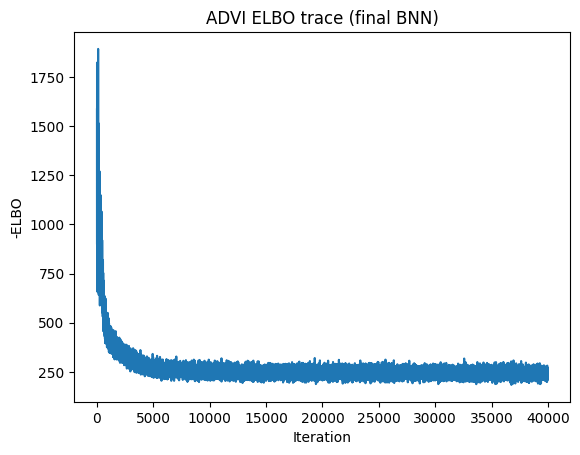

Sampling: [likelihood]


Output()

Final BNN training time: 104.55 seconds


Accuracy:  0.9118594231307757
Precision: 0.7525906735751295
Recall:    0.824405817665839
F1-Score:  0.786863043846284
AUC-ROC:   0.9598813236515595
Brier:     0.07836283691633857
Training time: 104.55 seconds
statistical test glm vs xgboost DelongTestResult(p_value=3.201271740360348e-82, log10_p_value=-81.49467745914859)
statistical test glm vs bnn DelongTestResult(p_value=6.673717386271542e-64, log10_p_value=-63.17563218847858)
statistical test bnn vs xgboost DelongTestResult(p_value=8.45644197234294e-07, log10_p_value=-6.072812326891073)


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.



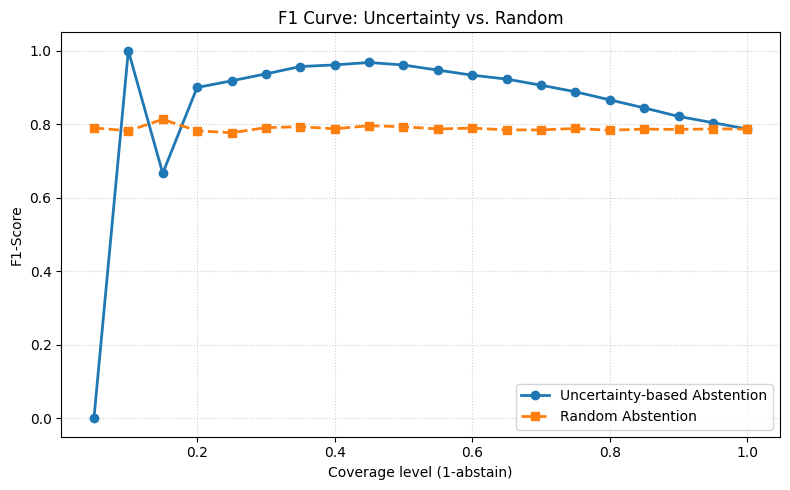

1.0 0.01 0.7000000000000002


In [10]:
#mb-bnn-final


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, brier_score_loss
from imblearn.over_sampling import SMOTE
import pymc as pm
import pytensor
import time
import random
from rocauc_comparison import delong_roc_test


# Scaling features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_mb)
X_val_s   = scaler.transform(X_val_mb)
X_test_s  = scaler.transform(X_test_mb)

# applying SMOTE on training data
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)
X_train_res = X_train_res
y_train_res = y_train_res

# BNN architecture
input_dim = X_train_mb.shape[1]
n_hidden   = 30
n_hidden_2 = 15

# ADVI learning rates (iterations fixed at 40000) and thresholds
advi_iters = 40000
learning_rates = [0.001, 0.01]
prior_sigmas = [0.5, 1.0]
thresholds = np.arange(0.5, 0.9, 0.05)

best_val_f1 = 0
best_lr = 0.001
best_threshold = 0.5
best_prior=0.5

for p in prior_sigmas:

    for lr in learning_rates:

        coords = {
            "hidden_layer":   np.arange(n_hidden),
            "hidden_layer_2": np.arange(n_hidden_2),
            "features":       np.arange(input_dim),
            "obs":            np.arange(X_train_res.shape[0])
        }
        with pm.Model(coords=coords) as model:
            X_data = pm.Data("X_data", X_train_res, dims=("obs", "features"))
            Y_data = pm.Data("Y_data", y_train_res, dims="obs")
            ann_input, ann_output = pm.Minibatch(X_data, Y_data, batch_size=1024)

            weights_in   = pm.Normal("weights_in",   mu=0, sigma=p, dims=("features", "hidden_layer"))
            weights_in_2 = pm.Normal("weights_in_2", mu=0, sigma=p, dims=("hidden_layer", "hidden_layer_2"))
            weights_out  = pm.Normal("weights_out",  mu=0, sigma=p, dims="hidden_layer_2")

            hidden   = pm.math.tanh(pm.math.dot(ann_input, weights_in))
            hidden_1 = pm.math.tanh(pm.math.dot(hidden, weights_in_2))
            output   = pm.math.sigmoid(pm.math.dot(hidden_1, weights_out))

            #bernoulli likelihood for modelling binary claim prediction
            likelihood = pm.Bernoulli("out", output, observed=ann_output, total_size=X_train_res.shape[0])

            approx = pm.fit(n=advi_iters, method="advi", obj_optimizer=pm.adam(learning_rate=lr),random_seed=42)
            trace = approx.sample(15000,random_seed=42)  

        # Predict on validation set
        test_coords = {
            "hidden_layer":   np.arange(n_hidden),
            "hidden_layer_2": np.arange(n_hidden_2),
            "features":       np.arange(input_dim),
            "obs_test":       np.arange(X_val_s.shape[0])
        }
        with pm.Model(coords=test_coords) as pred_model:
            ann_input = pm.Data("X_test_data", X_val_s, dims=("obs_test", "features"))
            w_in_1  = pm.Normal("weights_in",   mu=0, sigma=p, dims=("features", "hidden_layer"))
            w_1_2   = pm.Normal("weights_in_2", mu=0, sigma=p, dims=("hidden_layer", "hidden_layer_2"))
            w_2_out = pm.Normal("weights_out",  mu=0, sigma=p, dims="hidden_layer_2")
            act_1   = pm.math.tanh(pm.math.dot(ann_input, w_in_1))
            act_2   = pm.math.tanh(pm.math.dot(act_1, w_1_2))
            act_out = pm.math.sigmoid(pm.math.dot(act_2, w_2_out))
            p_out = pm.Deterministic("p_out", act_out)
            likelihood = pm.Bernoulli("likelihood", act_out, shape=X_val_s.shape[0])
            ppc_val = pm.sample_posterior_predictive(trace, var_names=["likelihood", "p_out"],random_seed=42)

        val_probs = ppc_val.posterior_predictive["p_out"].values.mean(axis=(0, 1))

        # Evaluate thresholds for best f1 score for maximum performance
        for thresh in thresholds:
            preds = (val_probs >= thresh).astype(int)
            f1 = f1_score(y_val, preds)
            if f1 > best_val_f1:
                best_val_f1 = f1
                best_lr = lr
                best_threshold = thresh
                best_prior=p

        print(f"  Best so far: F1={best_val_f1:.4f} with lr={best_lr}, thresh={best_threshold:.2f}, prior={best_prior}")


coords_final = {
    "hidden_layer":   np.arange(n_hidden),
    "hidden_layer_2": np.arange(n_hidden_2),
    "features":       np.arange(input_dim),
    "obs":            np.arange(X_train_res.shape[0])
}
with pm.Model(coords=coords_final) as final_model:
    X_data = pm.Data("X_data", X_train_res, dims=("obs", "features"))
    Y_data = pm.Data("Y_data", y_train_res, dims="obs")
    ann_input, ann_output = pm.Minibatch(X_data, Y_data, batch_size=1024)

    weights_in   = pm.Normal("weights_in",   mu=0, sigma=best_prior, dims=("features", "hidden_layer"))
    weights_in_2 = pm.Normal("weights_in_2", mu=0, sigma=best_prior, dims=("hidden_layer", "hidden_layer_2"))
    weights_out  = pm.Normal("weights_out",  mu=0, sigma=best_prior, dims="hidden_layer_2")

    hidden   = pm.math.tanh(pm.math.dot(ann_input, weights_in))
    hidden_1 = pm.math.tanh(pm.math.dot(hidden, weights_in_2))
    output   = pm.math.sigmoid(pm.math.dot(hidden_1, weights_out))

    likelihood = pm.Bernoulli("out", output, observed=ann_output, total_size=X_train_res.shape[0])

    start_time = time.time()
    approx_final = pm.fit(n=advi_iters, method="advi", obj_optimizer=pm.adam(learning_rate=best_lr),random_seed=42)
    training_time = time.time() - start_time
    plt.plot(approx_final.hist)
    plt.xlabel("Iteration")
    plt.ylabel("-ELBO")
    plt.title("ADVI ELBO trace (final BNN)")
    plt.show()

        
    trace_final = approx_final.sample(15000,random_seed=42)
print(f"Final BNN training time: {training_time:.2f} seconds")

test_coords_final = {
        "hidden_layer":   np.arange(n_hidden),
        "hidden_layer_2": np.arange(n_hidden_2),
        "features":       np.arange(input_dim),
        "obs_test":       np.arange(X_test_s.shape[0])
}
with pm.Model(coords=test_coords_final) as final_pred_model:
    ann_input = pm.Data("X_test_data", X_test_s, dims=("obs_test", "features"))
    w_in_1  = pm.Normal("weights_in",   mu=0, sigma=best_prior, dims=("features", "hidden_layer"))
    w_1_2   = pm.Normal("weights_in_2", mu=0, sigma=best_prior, dims=("hidden_layer", "hidden_layer_2"))
    w_2_out = pm.Normal("weights_out",  mu=0, sigma=best_prior, dims="hidden_layer_2")
    act_1   = pm.math.tanh(pm.math.dot(ann_input, w_in_1))
    act_2   = pm.math.tanh(pm.math.dot(act_1, w_1_2))
    act_out = pm.math.sigmoid(pm.math.dot(act_2, w_2_out))
    p_out = pm.Deterministic("p_out", act_out) 

    
    likelihood = pm.Bernoulli("likelihood", act_out, shape=X_test_s.shape[0])
    ppc_test = pm.sample_posterior_predictive(trace_final, var_names=["likelihood", "p_out"],random_seed=42)

posterior_samples= ppc_test.posterior_predictive["likelihood"].values
p_samples= ppc_test.posterior_predictive["p_out"].values 
test_probs_mbnn = p_samples.mean(axis=(0, 1))
epistemic = np.mean(p_samples**2, axis=(0, 1)) - test_probs_mbnn**2   # Kwon et al. (2020)
std_probs= p_samples.std(axis=(0, 1))  
test_preds = (test_probs_mbnn >= best_threshold).astype(int)
#printing results
print(f"Accuracy:  {accuracy_score(y_test, test_preds)}")
print(f"Precision: {precision_score(y_test, test_preds)}")
print(f"Recall:    {recall_score(y_test, test_preds)}")
print(f"F1-Score:  {f1_score(y_test, test_preds)}")
print(f"AUC-ROC:   {roc_auc_score(y_test, test_probs_mbnn)}")
print(f"Brier:     {brier_score_loss(y_test, test_probs_mbnn)}")
print(f"Training time: {training_time:.2f} seconds")
r1= delong_roc_test(y_test, test_probs_mglm,test_probs_mxg)
r2= delong_roc_test(y_test, test_probs_mglm,test_probs_mbnn)
r3= delong_roc_test(y_test, test_probs_mbnn,test_probs_mxg)
print('statistical test glm vs xgboost',r1 )
print('statistical test glm vs bnn',r2 )
print('statistical test bnn vs xgboost',r3)

y_test_array = np.asarray(y_test)

random.seed(42)
coverage = []
f1_scores = []

n = len(y_test)

for abstain_rate in np.arange(0,1,0.05):

    remove = int(n * abstain_rate)
    sorted_uncertainty = np.argsort(epistemic)[::-1]
    removed_uncertainty=sorted_uncertainty[remove:]

    # keep confident cases
    y_remaining = y_test_array[removed_uncertainty]
    prob_remaining = test_probs_mbnn[removed_uncertainty]

    pred_remaining = (prob_remaining >= best_threshold).astype(int)

    f1 = f1_score(y_remaining, pred_remaining)

    coverage.append(1-abstain_rate)
    f1_scores.append(f1)


coverage_random = []
f1_scores_random = []

n = len(y_test)

for abstain_rate in np.arange(0,1,0.05):

    remove = int(n * abstain_rate)
    remove_idx = random.sample(range(n), remove)
    filtered = [i for i in range(n) if i not in remove_idx]


    # keep cases after random removal
    y_remaining = y_test_array[filtered]
    prob_remaining = test_probs_mbnn[filtered]

    pred_remaining = (prob_remaining >= best_threshold).astype(int)

    f1 = f1_score(y_remaining, pred_remaining)

    coverage_random.append(1-abstain_rate)
    f1_scores_random.append(f1)

plt.figure(figsize=(8, 5))

plt.plot(coverage, f1_scores, marker='o', linewidth=2, label='Uncertainty-based Abstention')
plt.plot(coverage_random, f1_scores_random, marker='s', linestyle='--', linewidth=2, label='Random Abstention')

plt.xlabel('Coverage level (1-abstain)')
           
plt.ylabel('F1-Score')
plt.title('F1 Curve: Uncertainty vs. Random')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


plt.tight_layout()
plt.show()

np.save("test_probs_mbnn.npy", test_probs_mbnn)
np.save("epistemic.npy", epistemic)
print(best_prior, best_lr, best_threshold)